In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import joblib
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [12]:
# Load dataset
car = pd.read_csv("car_price_dataset.csv")

# Display first five records
car.head()

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
2,Maruti Suzuki Alto 800 Vxi,Maruti,2018,Ask For Price,"22,000 kms",Petrol
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,"3,25,000","28,000 kms",Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,"5,75,000","36,000 kms",Diesel


In [13]:
# Dataset shape
print("Dataset Shape:", car.shape)

# Dataset information
car.info()

# Statistical summary
car.describe(include="all")

Dataset Shape: (892, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 892 entries, 0 to 891
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        892 non-null    object
 1   company     892 non-null    object
 2   year        892 non-null    object
 3   Price       892 non-null    object
 4   kms_driven  840 non-null    object
 5   fuel_type   837 non-null    object
dtypes: object(6)
memory usage: 41.9+ KB


,name,company,year,Price,kms_driven,fuel_type
count,892,892,892,892,840,837
unique,525,48,61,274,258,3
top,Honda City,Maruti,2015,Ask For Price,"45,000 kms",Petrol
freq,13,235,117,35,30,440


In [14]:
print(car.columns.tolist())

['name', 'company', 'year', 'Price', 'kms_driven', 'fuel_type']


##Data cleaning and preprocessing

In [15]:
print("Missing Values:")
print(car.isnull().sum())

Missing Values:
name           0
company        0
year           0
Price          0
kms_driven    52
fuel_type     55
dtype: int64


In [16]:
print("Duplicate Rows:", car.duplicated().sum())

Duplicate Rows: 94


In [17]:
car = car.drop_duplicates()

print("Shape after removing duplicates:", car.shape)

Shape after removing duplicates: (798, 6)


In [18]:
# Remove commas and extract numeric price
car["Price"] = (
    car["Price"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.extract(r"(\d+(?:\.\d+)?)")[0]
)

car["Price"] = pd.to_numeric(car["Price"], errors="coerce")

In [19]:
car["kms_driven"] = (
    car["kms_driven"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.extract(r"(\d+)")[0]
)

car["kms_driven"] = pd.to_numeric(
    car["kms_driven"], errors="coerce"
)

In [20]:
car["year"] = pd.to_numeric(car["year"], errors="coerce")

In [21]:
car = car.dropna(
    subset=[
        "name",
        "company",
        "year",
        "Price",
        "kms_driven",
        "fuel_type"
    ]
)

car["year"] = car["year"].astype(int)
car["kms_driven"] = car["kms_driven"].astype(int)
car["Price"] = car["Price"].astype(float)

# Keep valid positive values
car = car[
    (car["Price"] > 0) &
    (car["kms_driven"] >= 0) &
    (car["year"] > 0)
]

# Use the first three words of car name
car["name"] = car["name"].astype(str).str.split().str[:3].str.join(" ")

# Reset index
car = car.reset_index(drop=True)

print("Data Cleaning Completed!")
print("Final Dataset Shape:", car.shape)

car.head()

Data Cleaning Completed!
Final Dataset Shape: (724, 6)


,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing,Hyundai,2007,80000.0,45000,Petrol
1,Mahindra Jeep CL550,Mahindra,2006,425000.0,40,Diesel
2,Hyundai Grand i10,Hyundai,2014,325000.0,28000,Petrol
3,Ford EcoSport Titanium,Ford,2014,575000.0,36000,Diesel
4,Ford Figo,Ford,2012,175000.0,41000,Diesel


##Exploratory Data Analysis (EDA)

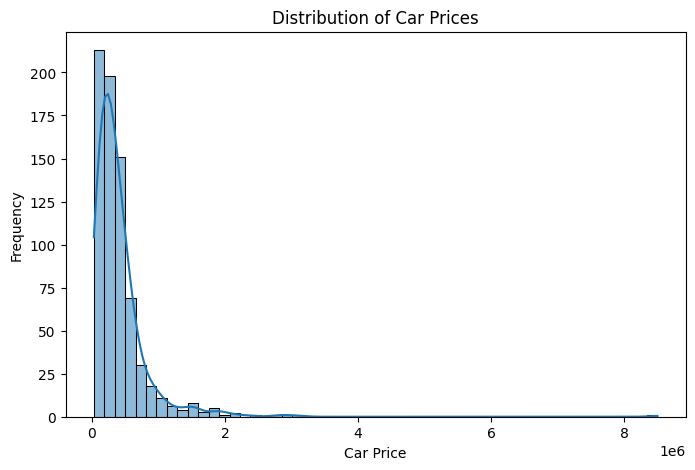

In [ ]:
plt.figure(figsize=(8, 5))  ##Price distribution

sns.histplot(car["Price"], kde=True)

plt.title("Distribution of Car Prices")
plt.xlabel("Car Price")
plt.ylabel("Frequency")

plt.show()

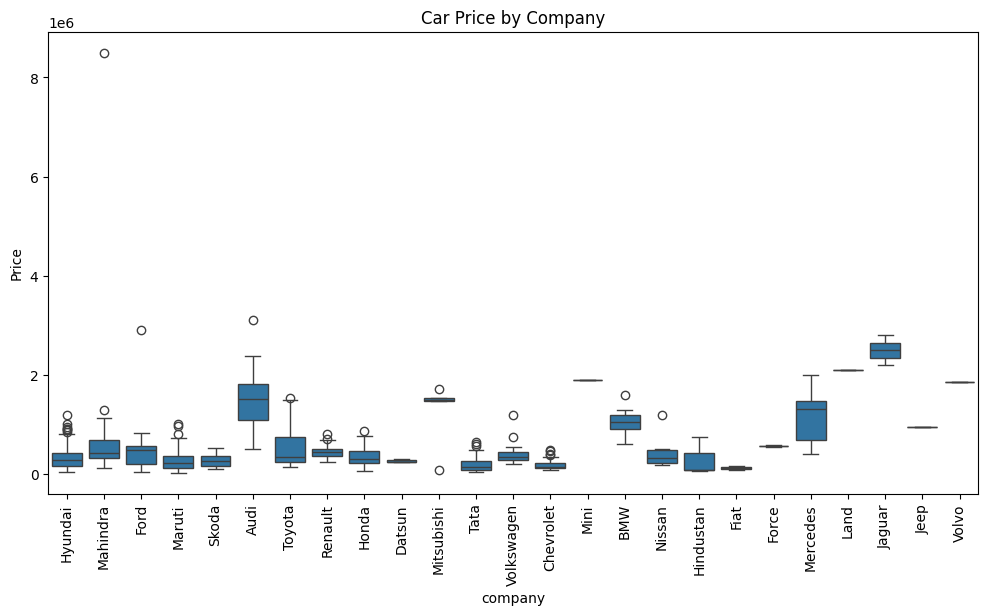

In [23]:
plt.figure(figsize=(12, 6)) ##Car price by company

sns.boxplot(data=car, x="company", y="Price")

plt.title("Car Price by Company")
plt.xticks(rotation=90)

plt.show()

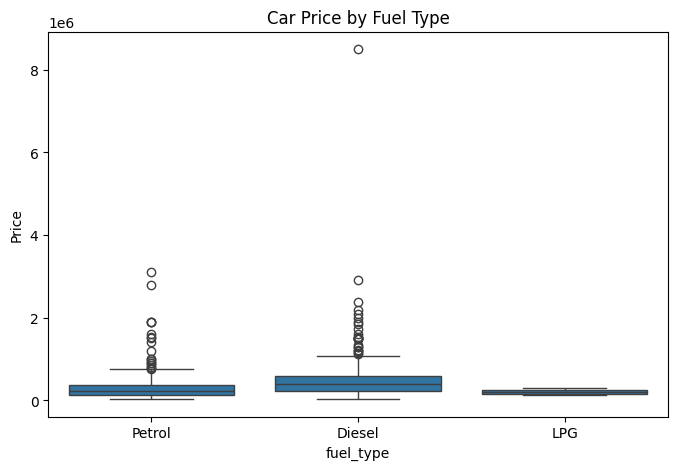

In [24]:
plt.figure(figsize=(8, 5))  ##Car price by fuel type

sns.boxplot(data=car, x="fuel_type", y="Price")

plt.title("Car Price by Fuel Type")

plt.show()

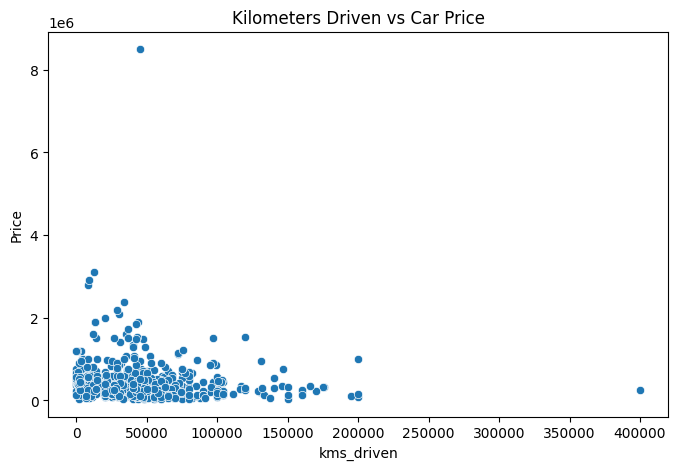

In [25]:
plt.figure(figsize=(8, 5)) ##Relationship between kilometers and price

sns.scatterplot(
    data=car,
    x="kms_driven",
    y="Price"
)

plt.title("Kilometers Driven vs Car Price")

plt.show()

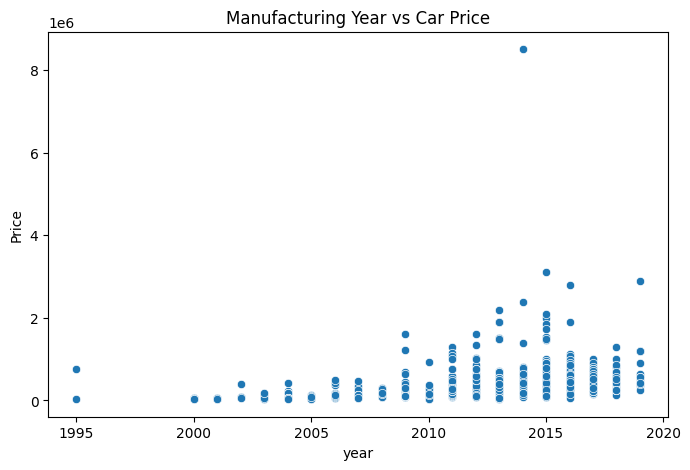

In [26]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=car,
    x="year",
    y="Price"
)

plt.title("Manufacturing Year vs Car Price")

plt.show()

Feature selection

In [27]:
# Independent variables
X = car[
    ["name", "company", "year", "kms_driven", "fuel_type"]
]

# Dependent variable
y = car["Price"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
                     name   company  year  kms_driven fuel_type
0     Hyundai Santro Xing   Hyundai  2007       45000    Petrol
1     Mahindra Jeep CL550  Mahindra  2006          40    Diesel
2       Hyundai Grand i10   Hyundai  2014       28000    Petrol
3  Ford EcoSport Titanium      Ford  2014       36000    Diesel
4               Ford Figo      Ford  2012       41000    Diesel

Target Variable:
0     80000.0
1    425000.0
2    325000.0
3    575000.0
4    175000.0
Name: Price, dtype: float64


In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.10,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (651, 5)
Testing Data: (73, 5)


In [29]:
# Define categorical and numerical columns
categorical_features = [
    "name",
    "company",
    "fuel_type"
]

numerical_features = [
    "year",
    "kms_driven"
]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessing created successfully!")

Preprocessing created successfully!


In [30]:
# Create ML pipeline
pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

print("Machine Learning Pipeline Created!")

Machine Learning Pipeline Created!


In [31]:
# Train model
pipe.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [32]:
# Predict using testing data
y_pred = pipe.predict(X_test)

print("Actual Prices:")
print(y_test.head())

print("\nPredicted Prices:")
print(y_pred[:5])

Actual Prices:
326    1000000.0
518    1065000.0
554     210000.0
33      489999.0
375     548900.0
Name: Price, dtype: float64

Predicted Prices:
[ 823323.11455853  838676.06223419   74679.90008684  367275.83439332
 2163424.03104261]


In [33]:
# Mean Absolute Error
mae = mean_absolute_error(y_test, y_pred)

# Root Mean Squared Error
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# R2 Score
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("R2 Accuracy:", r2 * 100, "%")

Model Evaluation Results
-------------------------
MAE: 165058.37641027692
RMSE: 267561.11497899186
R2 Score: 0.3552480784050669
R2 Accuracy: 35.52480784050669 %


In [34]:
results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

results.head(10)

,Actual Price,Predicted Price
0,1000000.0,8.233231e+05
1,1065000.0,8.386761e+05
2,210000.0,7.467990e+04
3,489999.0,3.672758e+05
4,548900.0,2.163424e+06
5,260000.0,5.292095e+05
6,160000.0,1.044147e+05
7,340000.0,2.202020e+05
8,689999.0,7.340473e+05
9,360000.0,3.205390e+05


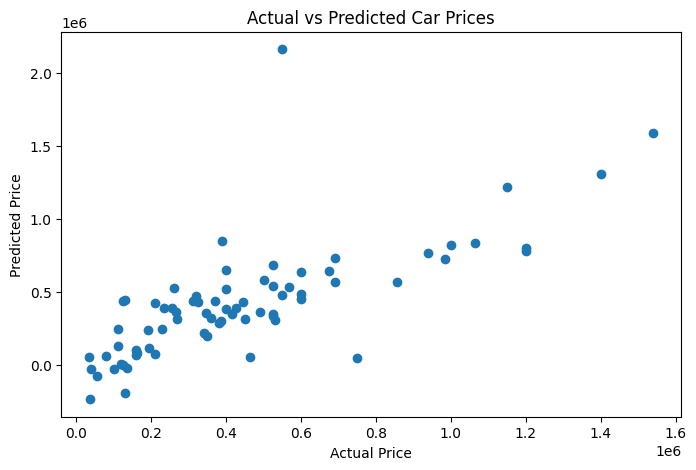

In [35]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted Car Prices")

plt.show()

Save the trained model

In [36]:
# Create model directory
os.makedirs("models", exist_ok=True)

# Save trained pipeline
joblib.dump(
    pipe,
    "models/LinearRegressionModel.pkl"
)

# Save cleaned dataset
car.to_csv("Cleaned_Car_data.csv", index=False)

print("Model Saved Successfully!")
print("Cleaned Dataset Saved Successfully!")

Model Saved Successfully!
Cleaned Dataset Saved Successfully!


In [37]:
# New car details
new_car = pd.DataFrame({
    "name": ["Maruti Suzuki Swift"],
    "company": ["Maruti"],
    "year": [2019],
    "kms_driven": [30000],
    "fuel_type": ["Petrol"]
})

# Predict car price
predicted_price = pipe.predict(new_car)

print("Estimated Car Price: ₹", round(predicted_price[0], 2))

Estimated Car Price: ₹ 430742.5
